# Assignment 9: Image Classification using Pretrained Vision Transformer and CNN

**Aim:** Use a small image dataset to compare a pretrained Vision Transformer (ViT) with a simple CNN.

**Dataset:** CIFAR-10, using a small subset of 2 classes (`airplane` and `automobile`) so training stays manageable.

**Models:**
- A small CNN trained from scratch.
- A pretrained ViT model fine-tuned for the same two classes.

**Evaluation:** Test accuracy and a simple comparison chart.

> Run in Google Colab with **Runtime → Change runtime type → T4 GPU** for faster execution. This notebook uses only a small subset of the dataset; results may vary between runs.

In [1]:
# Install the libraries needed for the pretrained Vision Transformer
!pip -q install transformers

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from transformers import AutoImageProcessor, ViTForImageClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 1. Load a small dataset

We use CIFAR-10, but keep only two classes and a small number of images. The images are resized to 224×224 for ViT; the CNN uses smaller 32×32 images.

In [3]:
# CIFAR-10 class IDs: airplane = 0, automobile = 1
NUM_TRAIN_PER_CLASS = 500
NUM_TEST_PER_CLASS = 200
BATCH_SIZE = 32

cnn_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_raw = datasets.CIFAR10(root="./data", train=True, download=True)
test_raw = datasets.CIFAR10(root="./data", train=False, download=True)

def indices_for_two_classes(dataset, per_class):
    chosen = []
    counts = {0: 0, 1: 0}
    for i, label in enumerate(dataset.targets):
        if label in counts and counts[label] < per_class:
            chosen.append(i)
            counts[label] += 1
        if all(counts[c] >= per_class for c in counts):
            break
    return chosen

train_indices = indices_for_two_classes(train_raw, NUM_TRAIN_PER_CLASS)
test_indices = indices_for_two_classes(test_raw, NUM_TEST_PER_CLASS)

# CNN dataset uses 32x32 images
cnn_train_full = datasets.CIFAR10(root="./data", train=True, download=False, transform=cnn_transform)
cnn_test_full = datasets.CIFAR10(root="./data", train=False, download=False, transform=cnn_transform)

cnn_train = Subset(cnn_train_full, train_indices)
cnn_test = Subset(cnn_test_full, test_indices)

train_loader = DataLoader(cnn_train, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(cnn_test, batch_size=BATCH_SIZE, shuffle=False)

print(f"CNN training images: {len(cnn_train)}")
print(f"CNN test images: {len(cnn_test)}")
print("Classes: airplane and automobile")

100%|██████████| 170M/170M [46:54<00:00, 60.6kB/s]


CNN training images: 1000
CNN test images: 400
Classes: airplane and automobile


## 2. Train a simple CNN

The CNN has two convolution layers, max pooling, and a fully connected output layer. We train it for only 3 epochs.

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

def train_cnn(model, loader, epochs=3):
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for images, labels in loader:
            # Convert CIFAR-10 labels to 0=airplane, 1=automobile
            labels = (labels == 1).long().to(device)
            images = images.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs}, loss: {total_loss/len(loader):.4f}")

train_cnn(cnn_model, train_loader, epochs=3)

Epoch 1/3, loss: 0.5826
Epoch 2/3, loss: 0.4418
Epoch 3/3, loss: 0.3870


In [5]:
def evaluate_cnn(model, loader):
    model.eval()
    correct, total = 0, 0
    start = time.time()
    with torch.no_grad():
        for images, labels in loader:
            labels = (labels == 1).long().to(device)
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total, (time.time() - start)

cnn_accuracy, cnn_time = evaluate_cnn(cnn_model, test_loader)
print(f"CNN test accuracy: {cnn_accuracy:.2f}%")
print(f"CNN inference time: {cnn_time:.2f} seconds")

CNN test accuracy: 83.75%
CNN inference time: 0.17 seconds


## 3. Fine-tune a pretrained Vision Transformer (ViT)

ViT is already pretrained on a large image dataset. We replace its classification head with a two-class head and fine-tune it briefly on our small subset.

In [6]:
MODEL_NAME = "google/vit-base-patch16-224-in21k"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
vit_model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    ignore_mismatched_sizes=True,
    id2label={0: "airplane", 1: "automobile"},
    label2id={"airplane": 0, "automobile": 1}
).to(device)

# ViT needs 224x224 images and the processor's normalization
vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

vit_train_full = datasets.CIFAR10(root="./data", train=True, download=False, transform=vit_transform)
vit_test_full = datasets.CIFAR10(root="./data", train=False, download=False, transform=vit_transform)
vit_train = Subset(vit_train_full, train_indices)
vit_test = Subset(vit_test_full, test_indices)

# Smaller batches help fit the ViT on common Colab GPUs
vit_train_loader = DataLoader(vit_train, batch_size=8, shuffle=True)
vit_test_loader = DataLoader(vit_test, batch_size=8, shuffle=False)

vit_optimizer = torch.optim.AdamW(vit_model.parameters(), lr=2e-5)

def train_vit(model, loader, epochs=1):
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for images, labels in loader:
            labels = (labels == 1).long().to(device)
            images = images.to(device)
            vit_optimizer.zero_grad()
            outputs = model(pixel_values=images, labels=labels)
            loss = outputs.loss
            loss.backward()
            vit_optimizer.step()
            total_loss += loss.item()
        print(f"ViT epoch {epoch+1}/{epochs}, loss: {total_loss/len(loader):.4f}")

train_vit(vit_model, vit_train_loader, epochs=1)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViT epoch 1/1, loss: 0.2531


In [ ]:
def evaluate_vit(model, loader):
    model.eval()
    correct, total = 0, 0
    start = time.time()
    with torch.no_grad():
        for images, labels in loader:
            labels = (labels == 1).long().to(device)
            outputs = model(pixel_values=images.to(device))
            predictions = outputs.logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total, (time.time() - start)

vit_accuracy, vit_time = evaluate_vit(vit_model, vit_test_loader)
print(f"ViT test accuracy: {vit_accuracy:.2f}%")
print(f"ViT inference time: {vit_time:.2f} seconds")

## 4. Compare the models

The chart compares test accuracy. Inference time is also displayed. Actual results are produced when you run the notebook.

MODEL COMPARISON
------------------------------------------
CNN  | Accuracy: 83.75% | Inference: 0.17s
ViT  | Accuracy: 98.00% | Inference: 4.61s


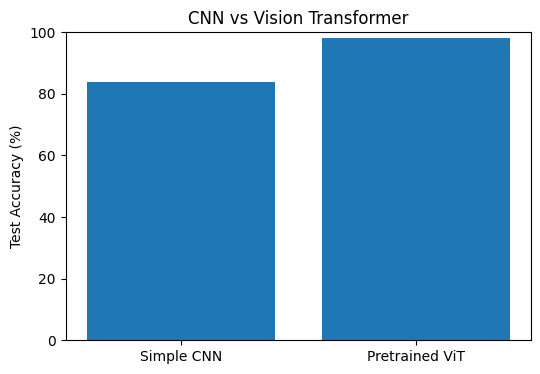

In [8]:
print("MODEL COMPARISON")
print("-" * 42)
print(f"CNN  | Accuracy: {cnn_accuracy:.2f}% | Inference: {cnn_time:.2f}s")
print(f"ViT  | Accuracy: {vit_accuracy:.2f}% | Inference: {vit_time:.2f}s")

plt.figure(figsize=(6, 4))
plt.bar(["Simple CNN", "Pretrained ViT"], [cnn_accuracy, vit_accuracy])
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs Vision Transformer")
plt.ylim(0, 100)
plt.show()

## 5. Conclusion

- The CNN is small and trained from scratch.
- ViT uses pretrained visual features and is fine-tuned for the same two classes.
- Compare the measured accuracy and inference time from your run.
- This is a simple demonstration; because ViT is pretrained and CNN is not, the comparison is not a fully controlled model-only comparison.